#Data Agreement

###Load the Data

In [ ]:
local_path="path/2/project"
LANGUAGES=["PT","BG","EN","RU",]

In [ ]:
import os
import zipfile

#Load IAA from JSON

In [ ]:
data_folder="path/2/data"
import json
import os
with open(os.path.join(data_folder,"annotations_all.json"), 'r') as f:
  data=json.load(f)


#FIX LANGUAGE CC

In [ ]:
#small bug on filenames. this line fixes it
for entry in data:
  if(entry["language"]=="CC"):
    entry["language"]="EN"

In [ ]:

res_dict=dict()

for entry in data:
  doc_id=entry["document"]
  if doc_id in res_dict.keys():
    res_dict[doc_id].append(entry)
  else:
    res_dict[doc_id]=list()
    res_dict[doc_id].append(entry)

In [ ]:
res_dict['A4_URW_BG_13718.txt'][2]


{'author': 'kzhelyazkov',
 'document': 'A4_URW_BG_13718.txt',
 'language': 'BG',
 'annotated': ['dominant_narrative',
  'role_type',
  'evidence',
  'Comment',
  'narrative_coarse',
  'narrative_finegrained'],
 'closed': None,
 'likely_completed': True,
 'dominant_narrative': [{'label': 'URW: Amplifying war-related fears: By continuing the war we risk WWIII',
   'text': 'Foreign',
   'begin': 0,
   'end': 7}],
 'role_type': [{'label': ['Innocent: Exploited'],
   'text': 'Руската федерация',
   'begin': 2737,
   'end': 2754},
  {'label': ['Antagonist: Deceiver'],
   'text': 'Бразилия',
   'begin': 2789,
   'end': 2797},
  {'label': ['Antagonist: Deceiver'],
   'text': 'Индия',
   'begin': 2800,
   'end': 2805}],
 'evidence': [{'text': 'Пълномащабното нахлуване на Руската федерация в Украйна постепенно прераства в Трета световна война',
   'begin': 101,
   'end': 200}],
 'raw': {},
 'Comment': [{'label': 'Конфликтът в Украйна започва да прераства в Трета световна война, поради подкрепата

Join and filter. Only annotations who were annotated with evidence and comments are consider. This excludes the annotators that annotate as dominant narrative "Other"

In [ ]:
expl_ann=dict()
count=0
for key,value in res_dict.items():
  for v in value:
    if ("dominant_narrative" in v["annotated"]) and ("evidence" in v["annotated"]):
      if(len(v["dominant_narrative"])>0) and (len(v["evidence"])>0):
        if("label" in v["dominant_narrative"][0].keys()):
          if(len(v["dominant_narrative"][0]["label"])>0):
            res_temp=dict()
            res_temp.update({"dominant_narrative":v["dominant_narrative"]})
            res_temp.update({"evidence":v["evidence"]})
            #print(res_temp)
            res_temp.update({"topic":v["dominant_narrative"][0]["label"].split(":")[0]})
            res_temp.update({"language":v["language"]})
            if key in expl_ann.keys():
              n_ann=len(expl_ann[key].keys())+1
              expl_ann[key].update({"ann_"+str(n_ann):res_temp})
            else:
              expl_ann[key]=dict()
              expl_ann[key].update({"ann_1":res_temp})



In [ ]:
expl_ann_no_evidence=dict()
count=0
for key,value in res_dict.items():
  for v in value:
    if ("dominant_narrative" in v["annotated"]):
      if(len(v["dominant_narrative"])>0):
        if("label" in v["dominant_narrative"][0].keys()):
          if(len(v["dominant_narrative"][0]["label"])>0):
            res_temp=dict()
            res_temp.update({"dominant_narrative":v["dominant_narrative"]})
            #res_temp.update({"evidence":v["evidence"]})
            #print(res_temp)
            res_temp.update({"topic":v["dominant_narrative"][0]["label"].split(":")[0]})
            res_temp.update({"language":v["language"]})
            if key in expl_ann_no_evidence.keys():
              n_ann=len(expl_ann_no_evidence[key].keys())+1
              expl_ann_no_evidence[key].update({"ann_"+str(n_ann):res_temp})
            else:
              expl_ann_no_evidence[key]=dict()
              expl_ann_no_evidence[key].update({"ann_1":res_temp})




In [ ]:
count=0
for key,value in expl_ann.items():
  if(len(value)>=2):
    count=count+1
    #print(key,len(value))
count

780

### Dominant Narrative

In [ ]:
import traceback

dom_iaa=list()
count_error=0
for key, value in expl_ann_no_evidence.items():
   # print(value.keys())
    if "ann_2" in value.keys():
      ann_1_narr=value["ann_1"]["dominant_narrative"][0]["label"]
      if(len(ann_1_narr.split(":"))==3):
        ann_1_narr=ann_1_narr.split(":")[1]
      elif(len(ann_1_narr.split(":"))==2):
        ann_1_narr=ann_1_narr.split(":")[1]
      elif(len(ann_1_narr.split(":"))==1):
        ann_1_narr=ann_1_narr
      else:
        print("ERROR")
        raise ValueError("ERROR")

      ann_2_narr=value["ann_2"]["dominant_narrative"][0]["label"]
      if(len(ann_2_narr.split(":"))==3):
        ann_2_narr=ann_2_narr.split(":")[1]
      elif(len(ann_2_narr.split(":"))==2):
        ann_2_narr=ann_2_narr.split(":")[1]
      elif(len(ann_2_narr.split(":"))==1):
        ann_2_narr=ann_2_narr
      else:
        print("ERROR")
        raise ValueError("ERROR")
      #ann_1_evidence=value["ann_1"]["evidence"]
      #ann_2_evidence=value["ann_2"]["evidence"]
      language=value["ann_1"]["language"]
      topic=value["ann_1"]["topic"]


      dom_iaa.append({"document":key,"topic":topic,"language":language,"ann1_narr":ann_1_narr,"ann2_narr":ann_2_narr}) #"ann1_evidence":ann_1_evidence,"ann2_evidence":ann_2_evidence})



In [ ]:
print("total_documents")
print(len(dom_iaa)+count_error)
print("#documents with two annotations in dominant narrative")
print(len(dom_iaa))
print("% of document for analysis")
print(len(dom_iaa)/(len(dom_iaa)+count_error)*100)

total_documents
1779
#documents with two annotations in dominant narrative
1779
% of document for analysis
100.0


## Using Simpledroff

In [ ]:
simple_data=list()
for entry in data:
  if ("dominant_narrative" in entry["annotated"]) and ("evidence" in entry["annotated"]):
    if(len(entry["dominant_narrative"])>0) and (len(entry["evidence"])>0):
      if("label" in entry["dominant_narrative"][0].keys()):
        if(len(entry["dominant_narrative"][0]["label"])>0):
          if(entry["dominant_narrative"][0]["label"]!="Other"):
              temp=dict()
              temp["document"]=entry["document"]
              temp["language"]=entry["language"]
              temp["topic"]=entry["dominant_narrative"][0]["label"].split(":")[0]
              temp["annotator_id"]=entry["author"]
              dom_narr=entry["dominant_narrative"][0]["label"]

              if(len(dom_narr.split(":"))==3):
                dom_narr=":".join(dom_narr.split(":")[:-1])
              elif(len(dom_narr.split(":"))==2):
                dom_narr=dom_narr
              elif(len(dom_narr.split(":"))==1):
                dom_narr=dom_narr
              else:
                print("ERROR")
                raise ValueError("ERROR")
              temp["dominant_narrative"]=dom_narr
              simple_data.append(temp)

In [ ]:
import pandas as pd
simple_data_df=pd.DataFrame.from_dict(simple_data)
simple_data_df

,document,language,topic,annotator_id,dominant_narrative
0,PT_01.txt,PT,CC,anaf,CC: Hidden plots by secret schemes of powerful...
1,PT_01.txt,PT,CC,gloriareis,CC: Criticism of climate movement
2,PT_02.txt,PT,URW,gloriareis,"URW: Discrediting the West, Diplomacy"
3,PT_03.txt,PT,URW,gloriareis,URW: Discrediting Ukraine
4,PT_04.txt,PT,URW,anaf,URW: Discrediting Ukraine
...,...,...,...,...,...
2075,RU-URW-1393.txt,RU,URW,mscordamaglia,URW: Blaming the war on others rather than the...
2076,RU-URW-1393.txt,RU,URW,ctroiani,URW: Praise of Russia
2077,RU-URW-1394.txt,RU,URW,lpalazzotti,URW: Discrediting Ukraine
2078,RU-URW-1394.txt,RU,URW,ctroiani,URW: Discrediting Ukraine


In [ ]:
!pip install simpledorff

In [ ]:
import simpledorff
for lang in LANGUAGES:
  simple_data_df_lang=simple_data_df[simple_data_df["language"]==lang]
  alpha=simpledorff.calculate_krippendorffs_alpha_for_df(simple_data_df_lang,experiment_col='document',
                                                 annotator_col='annotator_id',
                                                 class_col='dominant_narrative')
  print(lang,alpha)

PT 0.611989888046226
BG 0.7357107212774942
EN 0.4536420340416534
RU 0.41649029674964766


## HEATMAPS

In [ ]:
dom_iaa_df=pd.DataFrame.from_dict(dom_iaa)


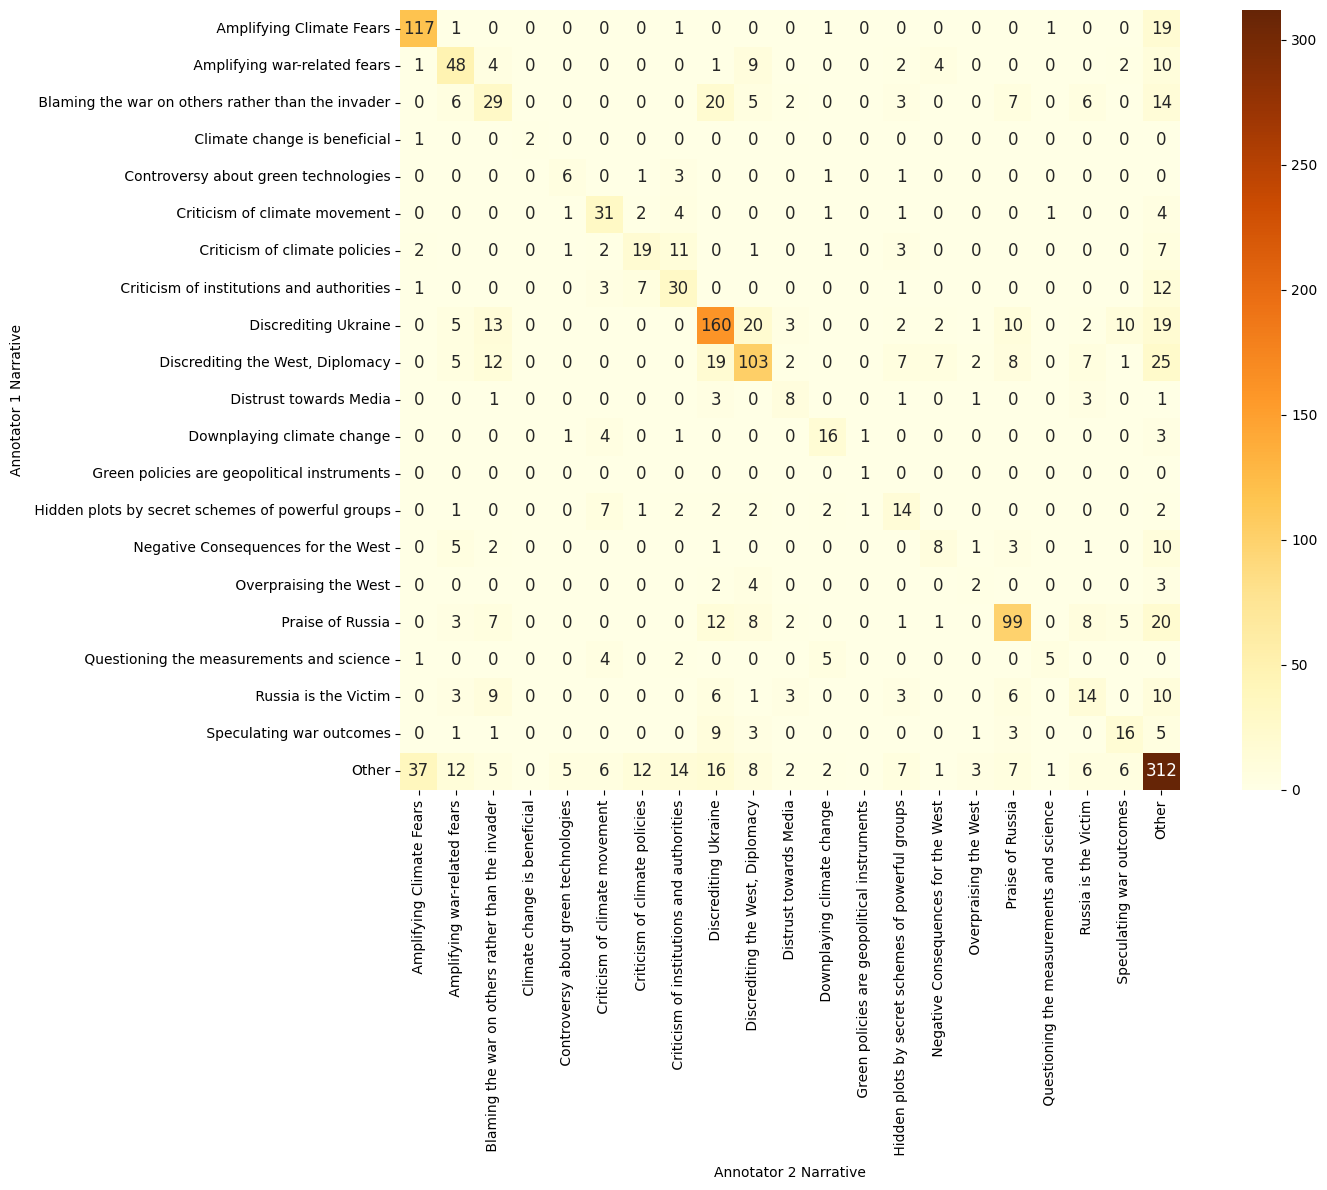

In [ ]:

# heatmap ann1_narr ann2_narr
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
# Create a cross-tabulation (contingency table) of the two narrative columns
contingency_table = pd.crosstab(dom_iaa_df['ann1_narr'], dom_iaa_df['ann2_narr'])
contingency_table
mask = np.triu(np.ones_like(contingency_table, dtype=bool),k=1)


# Plot the heatmap using the numerical contingency table
plt.figure(figsize=(16, 12)) # Adjust figure size as needed
sns.heatmap(
    contingency_table,
    #mask=mask,
    annot=True,
    cmap="YlOrBr",
    square=True,
    fmt=".0f",
    annot_kws={"size": 12}  # DECREASE FONT SIZE: Shrinks the numbers so they fit the cells
)
plt.xlabel('Annotator 2 Narrative')
plt.ylabel('Annotator 1 Narrative')
plt.tight_layout()
plt.savefig("heatmap_iaa_narrative")



In [ ]:
#convert contigency table to pandas dataframe
contingency_table=pd.DataFrame(contingency_table)
contingency_table

ann2_narr,Amplifying Climate Fears,Amplifying war-related fears,Blaming the war on others rather than the invader,Climate change is beneficial,Controversy about green technologies,Criticism of climate movement,Criticism of climate policies,Criticism of institutions and authorities,Discrediting Ukraine,"Discrediting the West, Diplomacy",...,Downplaying climate change,Green policies are geopolitical instruments,Hidden plots by secret schemes of powerful groups,Negative Consequences for the West,Overpraising the West,Praise of Russia,Questioning the measurements and science,Russia is the Victim,Speculating war outcomes,Other
ann1_narr,,,,,,,,,,,,,,,,,,,,,
Amplifying Climate Fears,117,1,0,0,0,0,0,1,0,0,...,1,0,0,0,0,0,1,0,0,19
Amplifying war-related fears,1,48,4,0,0,0,0,0,1,9,...,0,0,2,4,0,0,0,0,2,10
Blaming the war on others rather than the invader,0,6,29,0,0,0,0,0,20,5,...,0,0,3,0,0,7,0,6,0,14
Climate change is beneficial,1,0,0,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Controversy about green technologies,0,0,0,0,6,0,1,3,0,0,...,1,0,1,0,0,0,0,0,0,0
Criticism of climate movement,0,0,0,0,1,31,2,4,0,0,...,1,0,1,0,0,0,1,0,0,4
Criticism of climate policies,2,0,0,0,1,2,19,11,0,1,...,1,0,3,0,0,0,0,0,0,7
Criticism of institutions and authorities,1,0,0,0,0,3,7,30,0,0,...,0,0,1,0,0,0,0,0,0,12
Discrediting Ukraine,0,5,13,0,0,0,0,0,160,20,...,0,0,2,2,1,10,0,2,10,19


##Evidence

In [ ]:
import traceback

dom_iaa=list()
count_error=0
for key, value in expl_ann.items():
   # print(value.keys())
    if "ann_2" in value.keys():
      ann_1_narr=value["ann_1"]["dominant_narrative"][0]["label"]
      ann_2_narr=value["ann_2"]["dominant_narrative"][0]["label"]
      ann_1_evidence=value["ann_1"]["evidence"]
      ann_2_evidence=value["ann_2"]["evidence"]
      language=value["ann_1"]["language"]
      topic=value["ann_1"]["topic"]


      dom_iaa.append({"document":key,"topic":topic,"language":language,"ann1_narr":ann_1_narr,"ann2_narr":ann_2_narr, "ann1_evidence":ann_1_evidence,"ann2_evidence":ann_2_evidence})



In [ ]:

evidence_iaa=list()
count_error=0
for entry in dom_iaa:
      if(entry["ann1_narr"]==entry["ann2_narr"]):
        ann_1=entry["ann1_evidence"]
        ann_2=entry["ann2_evidence"]
        lang=entry["language"]
        key=entry["document"]
        topic=entry["topic"]

        evidence_iaa.append({"document":key,"language":lang,"topic":topic,"ann1":ann_1,"ann2":ann_2})



In [ ]:
evi=list()
for entry in evidence_iaa:
  if "ann2" in entry.keys():
    temp=dict()
    temp["document"]=entry["document"]
    temp["language"]=entry["language"]
    temp["topic"]=entry["topic"]
    temp["ann1"]=len(entry["ann1"])
    temp["ann2"]=len(entry["ann2"])
    evi.append(temp)

In [ ]:
print("total_documents")
print(len(evidence_iaa)+count_error)
print("#documents with two annotations in evidence where the annotators agree with the dominant narrative")
print(len(evidence_iaa))
print("% of document for analysis")
print(len(evidence_iaa)/(len(evidence_iaa)+count_error)*100)

total_documents
312
#documents with two annotations in evidence where the annotators agree with the dominant narrative
312
% of document for analysis
100.0


In [ ]:
import numpy as np
import krippendorff


def spans_to_token_labels(spans, text_length):
    """
    Convert span annotations into binary token labels.

    Parameters
    ----------
    spans : list of dict
        Each span must contain:
            {'begin': int, 'end': int}

        Assumes half-open intervals:
            [begin, end)

    text_length : int
        Total number of tokens or characters.

    Returns
    -------
    np.ndarray
        Binary vector of shape (text_length,)
        1 = evidence
        0 = non-evidence
    """
    labels = np.zeros(text_length, dtype=int)

    for span in spans:
        begin = span["begin"]
        end = span["end"]

        labels[begin:end] = 1

    return labels


def token_level_krippendorff_alpha(annotations, text_length):
    """
    Compute token-level Krippendorff's alpha for span annotations.

    Parameters
    ----------
    annotations : list of list of dict
        List of annotators.

        Example:
        [
            [{'begin': 10, 'end': 20}],
            [{'begin': 15, 'end': 25}]
        ]

    text_length : int
        Total number of tokens or characters.

    Returns
    -------
    dict
        {
            'alpha': float,
            'num_annotators': int,
            'text_length': int
        }
    """

    # Convert each annotator's spans into token labels
    reliability_data = []

    for annotator_spans in annotations:
        token_labels = spans_to_token_labels(
            annotator_spans,
            text_length
        )
        reliability_data.append(token_labels)

    reliability_data = np.array(reliability_data)

    # Compute Krippendorff's alpha
    alpha = krippendorff.alpha(
        reliability_data=reliability_data,
        level_of_measurement='nominal'
    )

    return {
        "alpha": alpha,
        "num_annotators": len(annotations),
        "text_length": text_length
    }

In [ ]:
def convertEntry(entry):
    entry_ann1=entry["ann1"]
    entry_ann2=entry["ann2"]
    entry_ann1=[{"begin":span["begin"],"end":span["end"]} for span in entry_ann1]
    entry_ann2=[{"begin":span["begin"],"end":span["end"]} for span in entry_ann2]
    return([entry_ann1,entry_ann2])


Compute evidence length and standard deviation per language

In [ ]:
import pandas as pd
results_mean_sd=list()
for entry in evidence_iaa:
  temp=dict()
  temp["lang"]=entry["language"]
  for ev in entry["ann1"]:
    temp["len"]=len(ev["text"])
    results_mean_sd.append(temp)

  temp=dict()
  temp["lang"]=entry["language"]
  for ev in entry["ann2"]:
    temp["len"]=len(ev["text"])
    results_mean_sd.append(temp)

#compute mean and standar deviation per language
# Compute mean and standard deviation per language
df_results = pd.DataFrame(results_mean_sd)

stats_per_language = (
    df_results
    .groupby("lang")["len"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
)

print(stats_per_language)
print(len(evidence_iaa))


  lang        mean         std  count
0   BG  186.000000  112.682864    382
1   EN  255.453125  174.036591    256
2   PT  107.032445   64.942872    863
3   RU  161.810624  101.141468    866
312


In [ ]:
dataset_folder="path/2/dataset"
texts_folder="path/2/texts"

In [ ]:
project_folder="path/2/projects"
LANGUAGES=["PT","BG","EN","RU"]

In [ ]:
import zipfile
import json
def getTextFromSofa(language,doc_id):

  res=dict()
  doc_folder=os.path.join(project_folder,language,"curation",doc_id)
  #if CURATION_USER.json does not exist
  if not os.path.exists(os.path.join(doc_folder,"CURATION_USER.json")):
    print("Does not exist")
    file=os.path.join(doc_folder,"CURATION_USER.zip")
    #unzip file
    with zipfile.ZipFile(file, 'r') as zip_ref:
      zip_ref.extractall(doc_folder)
  with open(os.path.join(doc_folder,"CURATION_USER.json"),"r",newline="") as f:
    raw = f.read()
    json_file=json.loads(raw)
  text=json_file["_referenced_fss"]["1"]["sofaString"]


  return text



In [ ]:
krip_list=list()
for evidence_iaa_entry in evidence_iaa:
  #print(evidence_iaa_entry)
  c_entry=convertEntry(evidence_iaa_entry)
  try:
    text=getTextFromSofa(evidence_iaa_entry["language"],evidence_iaa_entry["document"])
  except Exception as e:
    print(e)
    continue
  #print(c_entry)
  krip_list.append(float(token_level_krippendorff_alpha(c_entry,text_length=len(text))["alpha"]))



In [ ]:
sum(krip_list)/len()

In [ ]:
import numpy as np
import krippendorff

reliability_data = np.array(all_annotator_tokens)

alpha = krippendorff.alpha(
    reliability_data=reliability_data,
    level_of_measurement='nominal'
)

print(alpha)

In [ ]:
def exactMatch(ann1,ann2):
    spans1 = {(span['begin'], span['end']) for span in ann1}
    spans2 = {(span['begin'], span['end']) for span in ann2}
    print(spans1)
    # Calculate the matches
    matches = spans1.intersection(spans2)
    print(matches)
    num_matches = len(matches)

    # Calculate precision, recall, and F1-score
    precision = num_matches / len(spans1) if spans1 else 0
    recall = num_matches / len(spans2) if spans2 else 0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    # Return the results
    return {
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "num_matches": num_matches,
        "total_annotator1": len(spans1),
        "total_annotator2": len(spans2)
    }


In [ ]:
exact_match_results=list()
for doc in evidence_iaa:
  #print(doc)
  r=exactMatch(doc["ann1"],doc["ann2"])
  r.update({"lang":doc["language"]})
  r.update({"topic":doc["topic"]})

  exact_match_results.append(r)

In [ ]:
exact_match_results

In [ ]:
import pandas as pd
res_exact_df=pd.DataFrame.from_dict(exact_match_results
                                    )
res_exact_df

In [ ]:
res_exact_df.groupby(["lang","topic"])[["precision","recall","f1_score"]].mean()

In [ ]:
def partialMatch(annotator1, annotator2, threshold=0.5):
    """
    Compute inter-annotator agreement based on partial match.

    Parameters:
    - annotator1: List of spans from Annotator 1 (each span is a dictionary with 'begin' and 'end').
    - annotator2: List of spans from Annotator 2 (each span is a dictionary with 'begin' and 'end').
    - threshold: Overlap ratio required for two spans to be considered a match (default is 0.5).

    Returns:
    - dict: Agreement metrics (precision, recall, F1-score).
    """
    def calculate_overlap(span1, span2):
        """Calculate overlap between two spans."""
        start1, end1 = span1
        start2, end2 = span2
        overlap = max(0, min(end1, end2) - max(start1, start2))
        span1_length = end1 - start1
        span2_length = end2 - start2

        union = max(end1, end2) - min(start1, start2)
        return overlap / union

    # Extract spans as (begin, end) tuples
    spans1 = [(span['begin'], span['end']) for span in annotator1]
    spans2 = [(span['begin'], span['end']) for span in annotator2]

    # Find matches based on overlap
    matches = set()
    excluded=set()
    for span1 in spans1:

        best_score=0
        best_match=None

        for span2 in spans2:

          if span2 in excluded:
            continue

          score = calculate_overlap(span1, span2)

          if score >=threshold and score>best_score:
              best_score=score
              best_match=span2


        if best_match is not None:
            matches.add((span1, best_match))
            excluded.add(best_match)

    # Calculate precision, recall, and F1-score
    matched_spans1 = {m[0] for m in matches}
    matched_spans2 = {m[1] for m in matches}

    precision = len(matched_spans1) / len(spans1) if spans1 else 0
    recall = len(matched_spans2) / len(spans2) if spans2 else 0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    # Return the results
    return {
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "num_matches": len(matches),
        "total_annotator1": len(spans1),
        "total_annotator2": len(spans2),
        "threshold": threshold
    }


In [ ]:
partial_match_results=list()
for t in range(5,11,1):
  for doc in evidence_iaa:
    r=partialMatch(doc["ann1"],doc["ann2"],t/10)
    r.update({"lang":doc["language"]})
    r.update({"topic":doc["topic"]})

    partial_match_results.append(r)

In [ ]:
partial_match_results[0:10]

In [ ]:
res_partial_df=pd.DataFrame.from_dict(partial_match_results)
#remove other
res_partial_df=res_partial_df[res_partial_df["topic"]!="Other"]


In [ ]:
res_partial_df

In [ ]:
res_partial_df.groupby(["lang","topic","threshold"]).mean()

In [ ]:
import seaborn as sns

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
palette_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
palette = {
    "PT": palette_colors[0],
    "EN": palette_colors[1],
    "RU": palette_colors[2],
    "BG": palette_colors[3],
}

g=sns.FacetGrid(
    data=res_partial_df, col="topic")

g.map_dataframe(sns.lineplot, x="threshold", y="f1_score", hue="lang", palette=palette,errorbar=None)
g.add_legend()

g.savefig("partial_match")
plt.show()

In [ ]:
sns.lineplot(data=res_partial_df,x="threshold", y="f1_score",hue="lang",style="topic",errorbar=None,)

In [ ]:
sns.lineplot(data=res_partial_df,x="threshold", y="f1_score",hue="lang",style="topic",errorbar=None,)

In [ ]:
color_mapping = {
    "EN": "#1f77b4",  # Blue
    "PT": "#ff7f0e",  # Orange
    "BG": "#2ca02c",  # Green
    "HI": "#d62728",  # Red
    "RU": "#9467bd",  # Purple
}

res_partial_df=res_partial_df[res_partial_df["topic"]!="Other"]

g = sns.FacetGrid(data=res_partial_df, col="topic")  # Create separate plots for each language
g.map(sns.lineplot, "threshold", "f1_score", "lang", errorbar=None,palette=color_mapping)  # Use "topic" as the style or hue
g.add_legend()  # Add a legend
g.savefig("partial_match.png")